<a href="https://colab.research.google.com/github/mateus2911/esp32-rover-pavimento/blob/main/Pipeline_Dataset_Buracos.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Pipeline de Criação de Dataset de Buracos no Pavimento

Este notebook automatiza a preparação do ambiente, extração e filtragem de frames a partir de vídeos gravados com o carrinho (**Etapas 1 e 2**), gerando o arquivo de rastreamento (`controle_dataset.csv`) para a catalogação automática (**Etapa 3**).

## Célula 1 — Etapa 1: Montagem do Drive, Pastas e Parâmetros Globais

Conecta o Google Drive, cria toda a árvore de diretórios dentro de `Trabalho FInal Robotica`, verifica a existência da chave `GEMINI_API_KEY` nos *Colab Secrets* e centraliza os parâmetros de filtragem.

In [ ]:
import os
from pathlib import Path
from google.colab import drive, userdata

drive.mount('/content/drive')

BASE_DIR = Path('/content/drive/MyDrive/Trabalho FInal Robotica')

PASTAS = {
    "videos": BASE_DIR / "01_videos_brutos",
    "frames": BASE_DIR / "02_frames_extraidos",
    "cat_buraco": BASE_DIR / "03_dataset_catalogado" / "com_buraco",
    "cat_sem_buraco": BASE_DIR / "03_dataset_catalogado" / "sem_buraco",
    "cat_revisar": BASE_DIR / "03_dataset_catalogado" / "revisar",
    "logs": BASE_DIR / "04_controle_e_logs",
    "final": BASE_DIR / "05_dataset_final",
}

for caminho in PASTAS.values():
    caminho.mkdir(parents=True, exist_ok=True)

try:
    GEMINI_API_KEY = userdata.get('GEMINI_API_KEY')
    status_api = "Configurada com sucesso." if GEMINI_API_KEY else "Vazia."
except Exception:
    GEMINI_API_KEY = None
    status_api = "Ainda não configurada (configure em 'Secrets' antes da Etapa 3)."

CONFIG = {
    "fps_extracao": 3.0,
    "limiar_nitidez": 35.0,
    "limiar_similaridade": 0.96,
    "qualidade_jpeg": 95,
    "extensoes_video": (".mp4", ".avi", ".mov", ".mkv", ".mjpeg"),
    "confianca_alta": 0.85,
    "confianca_baixa": 0.15,
}

videos_encontrados = [
    p for p in PASTAS["videos"].rglob("*")
    if p.is_file() and p.suffix.lower() in CONFIG["extensoes_video"]
]

print(f"Estrutura verificada em: {BASE_DIR}")
print(f"Chave GEMINI_API_KEY: {status_api}")
print(f"Vídeos encontrados em '01_videos_brutos': {len(videos_encontrados)}")

if not videos_encontrados:
    print("\n[AVISO] Adicione seus vídeos (ou subpastas por prédio/corredor) em:")
    print(f"        {PASTAS['videos']}")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Estrutura verificada em: /content/drive/MyDrive/Trabalho FInal Robotica
Chave GEMINI_API_KEY: Ainda não configurada (configure em 'Secrets' antes da Etapa 3).
Vídeos encontrados em '01_videos_brutos': 1


In [ ]:
if CSV_CONTROLE.exists():
    CSV_CONTROLE.unlink()
for img in PASTAS["frames"].glob("*.jpg"):
    img.unlink()

## Célula 2 — Etapa 2: Extração, Anti-Blur, Deduplicação e Checkpoint CSV

Percorre todas as subpastas de `01_videos_brutos/`, extrai frames na taxa configurada, descarta imagens borradas ou redundantes, salva os frames aprovados com rastreabilidade de origem e registra tudo em `04_controle_e_logs/controle_dataset.csv`.

In [ ]:
import re
import unicodedata
import cv2
import numpy as np
import pandas as pd
from tqdm.notebook import tqdm

CSV_CONTROLE = PASTAS["logs"] / "controle_dataset.csv"

COLUNAS_CSV = [
    "frame_id",
    "ambiente",
    "video_origem",
    "frame_numero",
    "timestamp_seg",
    "nitidez",
    "similaridade_anterior",
    "caminho_frame",
    "status_catalogacao",
    "classe_predita",
    "prob_buraco",
    "destino_final",
]


def sanitizar_nome(texto: str) -> str:
    """Remove acentos, espaços e caracteres especiais para nomes de arquivo seguros."""
    texto = unicodedata.normalize("NFKD", texto).encode("ascii", "ignore").decode("ascii")
    texto = re.sub(r"[^a-zA-Z0-9_-]+", "_", texto.strip().lower())
    return texto.strip("_") or "geral"


def calcular_nitidez(frame_bgr: np.ndarray) -> float:
    """Calcula a variância do Laplaciano normalizada para largura de 320px."""
    h, w = frame_bgr.shape[:2]
    if w != 320:
        nova_h = max(1, int(h * (320 / w)))
        frame_redim = cv2.resize(frame_bgr, (320, nova_h), interpolation=cv2.INTER_AREA)
    else:
        frame_redim = frame_bgr
    cinza = cv2.cvtColor(frame_redim, cv2.COLOR_BGR2GRAY)
    return float(cv2.Laplacian(cinza, cv2.CV_64F).var())


def calcular_histograma_hsv(frame_bgr: np.ndarray) -> np.ndarray:
    """Gera histograma 3D (Matiz, Saturação e Brilho) para detectar mudanças no piso."""
    hsv = cv2.cvtColor(frame_bgr, cv2.COLOR_BGR2HSV)
    hist = cv2.calcHist([hsv], [0, 1, 2], None, [16, 16, 16], [0, 180, 0, 256, 0, 256])
    cv2.normalize(hist, hist, alpha=0, beta=1, norm_type=cv2.NORM_MINMAX)
    return hist


if CSV_CONTROLE.exists():
    df_controle = pd.read_csv(CSV_CONTROLE)
    videos_ja_processados = set(df_controle["video_origem"].unique())
else:
    df_controle = pd.DataFrame(columns=COLUNAS_CSV)
    videos_ja_processados = set()

lista_videos = sorted([
    p for p in PASTAS["videos"].rglob("*")
    if p.is_file() and p.suffix.lower() in CONFIG["extensoes_video"]
])

stats = {
    "videos_novos": 0,
    "videos_pulados": 0,
    "frames_amostrados": 0,
    "descartados_blur": 0,
    "descartados_redundantes": 0,
    "frames_salvos": 0,
    "valores_nitidez": [],
}

for caminho_video in tqdm(lista_videos, desc="Processando vídeos"):
    rel_path = str(caminho_video.relative_to(PASTAS["videos"]))

    if rel_path in videos_ja_processados:
        stats["videos_pulados"] += 1
        continue

    partes = caminho_video.relative_to(PASTAS["videos"]).parts
    ambiente = sanitizar_nome(partes[0]) if len(partes) > 1 else "raiz"
    nome_video = sanitizar_nome(caminho_video.stem)

    cap = cv2.VideoCapture(str(caminho_video))
    if not cap.isOpened():
        print(f"[ERRO] Não foi possível abrir o vídeo: {rel_path}")
        continue

    fps_video = cap.get(cv2.CAP_PROP_FPS)
    if not fps_video or fps_video <= 0 or np.isnan(fps_video):
        fps_video = 30.0

    intervalo_frames = max(1, int(round(fps_video / CONFIG["fps_extracao"])))
    frame_idx = 0
    ultimo_hist_salvo = None
    novos_registros = []

    while True:
        grabbed = cap.grab()
        if not grabbed:
            break

        if frame_idx % intervalo_frames == 0:
            ret, frame = cap.retrieve()
            if not ret or frame is None:
                frame_idx += 1
                continue

            stats["frames_amostrados"] += 1

            nitidez = calcular_nitidez(frame)
            stats["valores_nitidez"].append(nitidez)
            if nitidez < CONFIG["limiar_nitidez"]:
                stats["descartados_blur"] += 1
                frame_idx += 1
                continue

            hist_atual = calcular_histograma_hsv(frame)
            similaridade = 0.0
            if ultimo_hist_salvo is not None:
                similaridade = float(
                    cv2.compareHist(ultimo_hist_salvo, hist_atual, cv2.HISTCMP_CORREL)
                )
            if similaridade > CONFIG["limiar_similaridade"]:
                stats["descartados_redundantes"] += 1
                frame_idx += 1
                continue

            frame_id = f"{ambiente}__{nome_video}__f{frame_idx:06d}.jpg"
            caminho_saida = PASTAS["frames"] / frame_id

            cv2.imwrite(
                str(caminho_saida),
                frame,
                [cv2.IMWRITE_JPEG_QUALITY, CONFIG["qualidade_jpeg"]],
            )

            ultimo_hist_salvo = hist_atual
            stats["frames_salvos"] += 1

            novos_registros.append({
                "frame_id": frame_id,
                "ambiente": ambiente,
                "video_origem": rel_path,
                "frame_numero": frame_idx,
                "timestamp_seg": round(frame_idx / fps_video, 2),
                "nitidez": round(nitidez, 2),
                "similaridade_anterior": round(similaridade, 4),
                "caminho_frame": str(caminho_saida),
                "status_catalogacao": "pendente",
                "classe_predita": "",
                "prob_buraco": "",
                "destino_final": "",
            })

        frame_idx += 1

    cap.release()
    stats["videos_novos"] += 1

    if novos_registros:
        df_novos = pd.DataFrame(novos_registros)
        df_controle = pd.concat([df_controle, df_novos], ignore_index=True)
        df_controle.to_csv(CSV_CONTROLE, index=False)

print("\n" + "=" * 55)
print("RESUMO DA EXTRAÇÃO E FILTRAGEM (ETAPA 2)")
print("=" * 55)
print(f"Vídeos processados agora : {stats['videos_novos']}")
print(f"Vídeos pulados (já no log): {stats['videos_pulados']}")
print(f"Frames amostrados : {stats['frames_amostrados']}")
print(f"Descartados por blur : {stats['descartados_blur']}")
print(f"Descartados redundantes : {stats['descartados_redundantes']}")
print(f"Frames limpos salvos : {stats['frames_salvos']}")
print(f"Total acumulado no CSV : {len(df_controle)}")

if stats["valores_nitidez"]:
    arr = np.array(stats["valores_nitidez"])
    print(f"\nDistribuição de nitidez (limiar atual = {CONFIG['limiar_nitidez']}):")
    print(f" Mínima: {arr.min():.1f} | Mediana: {np.median(arr):.1f} | Máxima: {arr.max():.1f}")

Processando vídeos:   0%|          | 0/1 [00:00<?, ?it/s]


RESUMO DA EXTRAÇÃO E FILTRAGEM (ETAPA 2)
Vídeos processados agora : 1
Vídeos pulados (já no log): 0
Frames amostrados : 87
Descartados por blur : 14
Descartados redundantes : 6
Frames limpos salvos : 67
Total acumulado no CSV : 67

Distribuição de nitidez (limiar atual = 35.0):
 Mínima: 2.8 | Mediana: 70.3 | Máxima: 243.4


/tmp/ipykernel_7608/4282084124.py:165: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  df_controle = pd.concat([df_controle, df_novos], ignore_index=True)


## Célula 3 — Inspeção Visual Rápida (Calibração dos Limiares)

Exibe uma amostra aleatória dos frames aprovados junto com suas métricas para confirmar se o filtro de *blur* e redundância está bem ajustado antes de iniciar a Etapa 3.

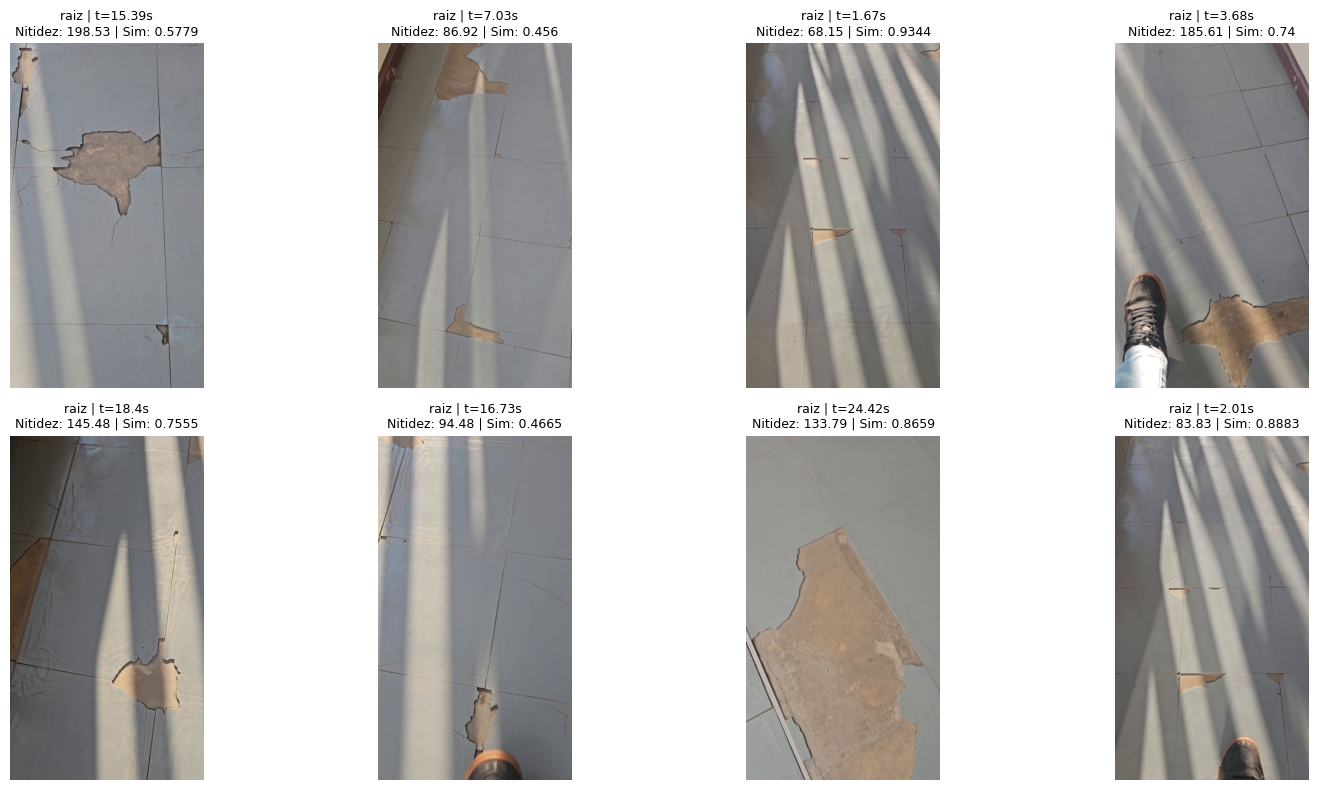

In [ ]:
import matplotlib.pyplot as plt

df_verificacao = pd.read_csv(CSV_CONTROLE)

if len(df_verificacao) == 0:
    print("Nenhum frame salvo ainda para visualizar.")
else:
    amostra = df_verificacao.sample(n=min(8, len(df_verificacao)), random_state=42)
    cols = 4
    rows = (len(amostra) + cols - 1) // cols

    fig, axes = plt.subplots(rows, cols, figsize=(16, 4 * rows))
    axes = np.array(axes).reshape(-1)

    for ax, (_, linha) in zip(axes, amostra.iterrows()):
        img = cv2.imread(linha["caminho_frame"])
        if img is not None:
            img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
            ax.imshow(img_rgb)
            ax.set_title(
                f"{linha['ambiente']} | t={linha['timestamp_seg']}s\n"
                f"Nitidez: {linha['nitidez']} | Sim: {linha['similaridade_anterior']}",
                fontsize=9,
            )
        ax.axis("off")

    for ax in axes[len(amostra):]:
        ax.axis("off")

    plt.tight_layout()
    plt.show()